In [ ]:
#Desi Armanda Sari

#import library yang dibutuhkan
import tensorflow as tf
from tensorflow import keras
import keras.utils as image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
from google.colab import files
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import zipfile, os

In [ ]:
#Mengunduh dataset
!wget --no-check-certificate \
  https://github.com/dicodingacademy/assets/releases/download/release/rockpaperscissors.zip

--2025-09-05 17:13:55--  https://github.com/dicodingacademy/assets/releases/download/release/rockpaperscissors.zip
Resolving github.com (github.com)... 20.27.177.113
Connecting to github.com (github.com)|20.27.177.113|:443... connected.
HTTP request sent, awaiting response... 302 Found
Resolving release-assets.githubusercontent.com (release-assets.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to release-assets.githubusercontent.com (release-assets.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 322873683 (308M) [application/octet-stream]
Saving to: ‘rockpaperscissors.zip’

rockpaperscissors.z 100%[===================>] 307.92M  30.7MB/s    in 11s     

2025-09-05 17:14:06 (28.8 MB/s) - ‘rockpaperscissors.zip’ saved [322873683/322873683]



In [ ]:
#Extract file
local_zip = 'rockpaperscissors.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/release')
zip_ref.close()

In [ ]:
base_dir = '/release/rockpaperscissors/rps-cv-images'
os.listdir(base_dir)

['paper', 'rock', 'scissors', 'README_rpc-cv-images.txt']

In [ ]:
#Membagi dataset
train_datagen = ImageDataGenerator(
                    rescale=1./255,
                    rotation_range=20,
                    horizontal_flip=True,
                    shear_range = 0.2,
                    fill_mode = 'nearest',
                    validation_split = 0.4)

train_generator = train_datagen.flow_from_directory(
                    base_dir,
                    target_size=(150,150),
                    batch_size=5,
                    seed=42,
                    subset="training"
)
validation_generator = train_datagen.flow_from_directory(
                    base_dir,
                    target_size=(150,150),
                    batch_size=5,
                    seed=42,
                    shuffle=False,
                    subset="validation"
)

Found 1314 images belonging to 3 classes.
Found 874 images belonging to 3 classes.


In [ ]:
 #Membuat model
 model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation="relu", input_shape=(150,150,3)),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(128, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.SGD(nesterov=True),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Training
model.fit(
    train_generator,
    steps_per_epoch=60,
    epochs=20,
    validation_data=validation_generator,
    validation_steps=20,
    verbose=2,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="loss",
            patience=10,
            restore_best_weights=True,
        )
    ]
)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


60/60 - 19s - 324ms/step - accuracy: 0.3333 - loss: 1.1010 - val_accuracy: 0.7000 - val_loss: 1.0543
Epoch 2/20
60/60 - 18s - 305ms/step - accuracy: 0.4381 - loss: 1.0657 - val_accuracy: 0.4700 - val_loss: 1.0267
Epoch 3/20
60/60 - 18s - 304ms/step - accuracy: 0.5367 - loss: 0.9767 - val_accuracy: 0.0000e+00 - val_loss: 1.9618
Epoch 4/20
60/60 - 18s - 306ms/step - accuracy: 0.6233 - loss: 0.8836 - val_accuracy: 0.8000 - val_loss: 0.6230
Epoch 5/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


60/60 - 11s - 177ms/step - accuracy: 0.6174 - loss: 0.8468 - val_accuracy: 0.6800 - val_loss: 0.8217
Epoch 6/20
60/60 - 18s - 299ms/step - accuracy: 0.6433 - loss: 0.7670 - val_accuracy: 0.3100 - val_loss: 1.3665
Epoch 7/20
60/60 - 20s - 341ms/step - accuracy: 0.6867 - loss: 0.7656 - val_accuracy: 0.8600 - val_loss: 0.5773
Epoch 8/20
60/60 - 18s - 298ms/step - accuracy: 0.7233 - loss: 0.7094 - val_accuracy: 0.8600 - val_loss: 0.4209
Epoch 9/20
60/60 - 18s - 307ms/step - accuracy: 0.7533 - loss: 0.6183 - val_accuracy: 0.9500 - val_loss: 0.2351
Epoch 10/20
60/60 - 10s - 171ms/step - accuracy: 0.7544 - loss: 0.6306 - val_accuracy: 0.6800 - val_loss: 0.7910
Epoch 11/20
60/60 - 75s - 1s/step - accuracy: 0.7533 - loss: 0.5795 - val_accuracy: 0.3500 - val_loss: 1.2191
Epoch 12/20
60/60 - 18s - 297ms/step - accuracy: 0.8127 - loss: 0.5273 - val_accuracy: 0.6600 - val_loss: 0.7406
Epoch 13/20
60/60 - 18s - 308ms/step - accuracy: 0.8133 - loss: 0.5105 - val_accuracy: 0.8700 - val_loss: 0.3986
Ep

In [ ]:
# Testing
model.evaluate(validation_generator)

175/175 [==============================] - 18s 103ms/step - loss: 0.1803 - accuracy: 0.9474


[0.18028028309345245, 0.9473684430122375]

Saving WhatsApp Image 2025-09-06 at 00.27.27_2dd0a70e.jpg to WhatsApp Image 2025-09-06 at 00.27.27_2dd0a70e.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
WhatsApp Image 2025-09-06 at 00.27.27_2dd0a70e.jpg
classes [[1. 0. 0.]]
paper


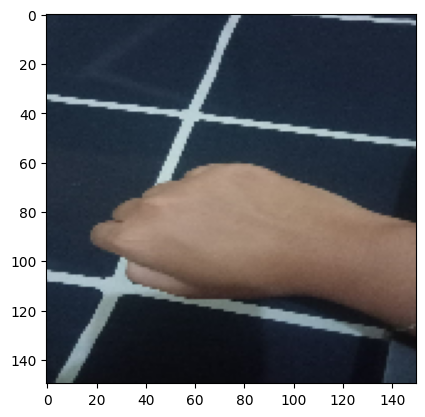

In [ ]:
%matplotlib inline

uploaded = files.upload()

for fn in uploaded.keys():

  path = fn
  img = image.load_img(path, target_size=(150,150))
  imgplot = plt.imshow(img)
  x = image.img_to_array(img)
  x = np.expand_dims(x, axis=0)

  images = np.vstack([x])
  classes = model.predict(images, batch_size=10)

  print(fn)
  print('classes', classes)
  if classes[0, 0]:
    print('paper')
  elif classes[0, 1]:
    print('rock')
  elif classes[0, 2]:
    print('scissors')